# What does covariance find that composition does not?

**Why.** Composition is a property of cell means, so expression wins it by construction (`metric_variants.ipynb`:
expression reaches 87 % of the composition ceiling, d_B 79 %). This notebook scores the search on four targets that
mean expression cannot see directly.

| Target | Per-tile ground truth | Why covariance might see it |
|---|---|---|
| 1. Arrangement | contact excess between cell classes: for each class pair, the share of the tile's 6-NN edges minus its expectation under random labelling of the same cells | segmentation spillover gives cells in contact some of each other's transcripts, so contact shows up as co-expression of two types' markers |
| 2. Cell state | (a) within-class sub-states: k-means (k = 3) on each class's cells, the state fractions per class; (b) cycling: the share of each class's cells with MKI67, TOP2A or CENPF detected | the means show *how much*, not *which cells* |
| 3. Morphology | 10/25/50/75/90 % quantiles of log cell area, log nucleus area and nucleus/cell ratio (no transcripts used) | a modality independent of expression; partly confounded with cell size |
| 4. Robustness | (a) query counts thinned to half (binomial); (b) each gene scaled by a fixed capture factor e^N(0, 0.5) (a platform effect) | correlations ignore per-gene scale; means do not |

**Setting for 1–3: re-ranking**, as `rerank.ipynb`, because expression dominates open search. The query is half A of
a held-out tile; each ranker picks 10 of expression's 50 nearest index tiles. Targets of the query come from cells the
query never saw where they depend on expression (cell state: half B) and from the whole tile otherwise (positions,
morphology). Score = similarity of each hit's target to the query's, as the difference from expression's own top 10.
Controls: **Composition** (the 10 candidates closest to half A in cell-class composition) shows what composition alone
buys; **Oracle** (the 10 closest in the target itself) is the ceiling; **Random** is the mean over the 50.

**Setting for 4: open search.** The full held-out tile, perturbed, queries the whole index; score = overlap of its top
10 with the same distance's top 10 for the unperturbed query, and the composition lift kept.

Rankers: Expression, Variance only, d_B (the method), d_B size-normalised and Correlation only (references from
`metric_variants.ipynb`; all on the raw layout's blocks). Breast, cap 200, seeds 0–4, 10 % held out.

**Pass rules, fixed before the run.**
- Targets 1–3: d_B's gain over expression's top 10 is positive on all 5 seeds, Wilcoxon p < 0.01, and larger than the
  Composition control's gain.
- Target 4: d_B's top-10 overlap is ≥ expression's + 0.10, for each perturbation.

Experiment code only; `src/` is unchanged.

In [1]:
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.stats import wilcoxon
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

ROOT = Path.cwd().resolve()
while not (ROOT / "datasets.yaml").exists():
    ROOT = ROOT.parent
for p in (ROOT / "src", ROOT):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
import paths
import spindle_dev as sd
from spindle_dev.metrics import shrink_cov, spd_to_correlation
from spindle_dev.preprocessing import build_quadtree_tiles, topvar_genes
from spindle_dev.naive import BlockVectorizer

logging.getLogger("spindle_dev").setLevel(logging.WARNING)
KEY, SEEDS, TEST_RATIO, CAP = "breast_cancer", [0, 1, 2, 3, 4], 0.1, 200
TOP, N_CAND, KNN, N_STATES = 10, 50, 6, 3
CYCLING = ["MKI67", "TOP2A", "CENPF"]
CAPTURE_SD = 0.5
RANKERS = ["Expression", "Variance only", "d_B", "d_B size-normalised", "Correlation only"]
CONTROLS = ["Composition", "Oracle", "Random"]
TARGETS = ["arrangement", "sub-states", "cycling", "morphology"]
PERTURB = ["depth ½", "gene capture"]
COLORS = {"Expression": "#EE6677", "Variance only": "#999999", "d_B": "#4477AA", "d_B size-normalised": "#66CCEE",
          "Correlation only": "#228833", "Composition": "#CCBB44", "Oracle": "#333333", "Random": "#BBBBBB"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## Data and per-cell labels

In [2]:
adata = sd.load_adata(paths.dataset_path(KEY))
max_genes = paths.dataset_max_genes(KEY)
genes, gene_idx = topvar_genes(adata, G=min(max_genes, adata.n_vars))
genes = np.asarray(genes).astype(str)
p = len(genes)
Xg = adata.X[:, gene_idx]
Xg = Xg.tocsr() if sp.issparse(Xg) else sp.csr_matrix(Xg)
xy = np.asarray(adata.obsm["spatial"], dtype=np.float64)
lib = np.asarray(adata.X.sum(1)).ravel().astype(np.float64)
scale = np.median(lib) / np.maximum(lib, 1)
N = adata.n_obs

CLASSES = [
    ("Invasive tumour", ["Invasive_Tumor", "Prolif_Invasive_Tumor", "T_Cell_&_Tumor_Hybrid"]),
    ("DCIS", ["DCIS_1", "DCIS_2"]),
    ("Myoepithelial", ["Myoepi_ACTA2+", "Myoepi_KRT15+"]),
    ("Stromal", ["Stromal", "Stromal_&_T_Cell_Hybrid"]),
    ("Endothelial / perivascular", ["Endothelial", "Perivascular-Like"]),
    ("Myeloid", ["Macrophages_1", "Macrophages_2", "IRF7+_DCs", "LAMP3+_DCs", "Mast_Cells"]),
    ("T cells", ["CD4+_T_Cells", "CD8+_T_Cells"]),
    ("B cells", ["B_Cells"]),
]
to_class = {t: i for i, (_, members) in enumerate(CLASSES) for t in members}
cell_cls = np.array([to_class[t] for t in adata.obs["Cluster"].astype(str)])
NC = len(CLASSES)
PAIRS = np.triu_indices(NC)                                        # class pairs incl. same-class, 36

# 2a: sub-states, k-means on 20 PCs of log-normalised counts within each class
L_all = np.log1p(Xg.multiply(scale[:, None]).toarray())
state = np.zeros(N, dtype=int)
for c in range(NC):
    r = np.flatnonzero(cell_cls == c)
    Z = PCA(min(20, p), random_state=0).fit_transform(L_all[r])
    state[r] = KMeans(N_STATES, n_init=4, random_state=0).fit_predict(Z)
del L_all
# 2b: cycling cells
cyc_idx = [int(np.flatnonzero(genes == g)[0]) for g in CYCLING if g in genes]
cycling = np.asarray((Xg[:, cyc_idx] > 0).sum(1)).ravel() > 0
# 3: morphology
morph = np.column_stack([np.log(adata.obs["cell_area"].to_numpy(float)),
                         np.log(adata.obs["nucleus_area"].to_numpy(float) + 1e-3),
                         (adata.obs["nucleus_area"] / adata.obs["cell_area"]).to_numpy(float)])
# 1: 6-NN graph over all cells (undirected edge list)
nbr = NearestNeighbors(n_neighbors=KNN + 1).fit(xy).kneighbors(xy, return_distance=False)[:, 1:]
E = np.unique(np.sort(np.column_stack([np.repeat(np.arange(N), KNN), nbr.ravel()]), axis=1), axis=0)
print(f"{N} cells, {p} genes; cycling markers {[g for g in CYCLING if g in genes]}: {cycling.mean():.1%} of cells; "
      f"{len(E)} 6-NN edges")

159226 cells, 313 genes; cycling markers ['MKI67', 'TOP2A', 'CENPF']: 33.6% of cells; 547472 6-NN edges


## Tiles and per-tile targets

In [3]:
tiles = build_quadtree_tiles(xy, max_pts=CAP, min_side=0.0, max_depth=40)
K = len(tiles)
tile_of = np.full(N, -1)
for i, t in enumerate(tiles):
    tile_of[t.idx] = i
inside = (tile_of[E[:, 0]] == tile_of[E[:, 1]]) & (tile_of[E[:, 0]] >= 0)
E_in, E_tile = E[inside], tile_of[E[inside, 0]]


def composition(idx):
    c = np.bincount(cell_cls[idx], minlength=NC).astype(float)
    return c / max(c.sum(), 1)


def arrangement(i):
    # contact excess per class pair: observed share of the tile's internal edges minus the share expected if the
    # same cells' labels were placed at random
    e = E_in[E_tile == i]
    n = np.bincount(cell_cls[tiles[i].idx], minlength=NC).astype(float)
    tot = n.sum()
    if len(e) == 0 or tot < 2:
        return np.full(len(PAIRS[0]), np.nan)
    a, b = np.sort(np.column_stack([cell_cls[e[:, 0]], cell_cls[e[:, 1]]]), axis=1).T
    M = np.zeros((NC, NC))
    np.add.at(M, (a, b), 1)
    obs = M[PAIRS] / len(e)
    exp = np.where(PAIRS[0] == PAIRS[1], n[PAIRS[0]] * (n[PAIRS[0]] - 1), 2 * n[PAIRS[0]] * n[PAIRS[1]]) / (tot * (tot - 1))
    return obs - exp


def substates(idx):
    # (NC, N_STATES) state fractions within each class, and the class counts
    M = np.zeros((NC, N_STATES))
    np.add.at(M, (cell_cls[idx], state[idx]), 1)
    n = M.sum(1)
    return M / np.maximum(n, 1)[:, None], n


def cycling_by_class(idx):
    n = np.bincount(cell_cls[idx], minlength=NC).astype(float)
    k = np.bincount(cell_cls[idx], weights=cycling[idx].astype(float), minlength=NC)
    return k / np.maximum(n, 1), n


def morphology(idx):
    return np.nanquantile(morph[idx], [0.1, 0.25, 0.5, 0.75, 0.9], axis=0).T.ravel()


comp = np.stack([composition(t.idx) for t in tiles])
ARR = np.stack([arrangement(i) for i in range(K)])
SUB = [substates(t.idx) for t in tiles]
CYC = [cycling_by_class(t.idx) for t in tiles]
MOR = np.stack([morphology(t.idx) for t in tiles])
MOR_SD = MOR.std(0)
print(f"{K} tiles, median {int(np.median([t.idx.size for t in tiles]))} cells, "
      f"median {int(np.median(np.bincount(E_tile, minlength=K)))} internal edges per tile")


def similarity(target, tq, hits):
    # similarity of each hit's target to the query's (higher = closer)
    if target == "arrangement":
        return -np.abs(ARR[hits] - tq).sum(1)
    if target == "morphology":
        return -np.abs((MOR[hits] - tq) / MOR_SD).mean(1)
    S = SUB if target == "sub-states" else CYC
    fq, nq = tq
    w = nq / nq.sum()
    out = np.empty(len(hits))
    for j, h in enumerate(hits):
        fh, nh = S[h]
        ok = (nq >= 3) & (nh >= 3)
        if not ok.any():
            out[j] = np.nan
            continue
        d = np.abs(fq - fh).sum(1) / 2 if target == "sub-states" else np.abs(fq - fh)
        out[j] = -(w[ok] * d[ok]).sum() / w[ok].sum()
    return out


def query_target(target, idx_all, idx_b):
    if target == "arrangement":
        return ARR[tile_of[idx_all[0]]]
    if target == "morphology":
        return morphology(idx_all)
    return substates(idx_b) if target == "sub-states" else cycling_by_class(idx_b)

[2026-11-01 05:26:04,987] INFO spindle_dev.preprocessing: build_quadtree_tiles: dropping 37 low-density tile(s) (1865 spots)


2044 tiles, median 67 cells, median 190 internal edges per tile


## Run

In [4]:
def cells(idx):
    return Xg[idx].toarray().astype(np.float64)


def cov_of(Z):
    # as preprocessing._tile_cov: ML covariance + 1e-6 on the diagonal, then shrunk once (alpha = 0.1)
    mu = Z.mean(0)
    S = Z.T @ Z / Z.shape[0] - np.outer(mu, mu)
    S.flat[::p + 1] += 1e-6
    return shrink_cov(S)


def query_features(X, idx):
    # a query's features: log mean, log variances, and per niche the three covariance vectors
    C, Cn = cov_of(X), cov_of(X * scale[idx, None])
    R = spd_to_correlation(C)
    return {"exp": np.log1p(X.mean(0)) / np.sqrt(p), "var": np.log(np.diag(C)) / np.sqrt(p),
            "vec": {k: (v.vector(C), v.vector(Cn), v.vector(R)) for k, v in VEC.items()}}


def distances(f, rows=None):
    # every ranker's distance from query features f to index tiles (positions into train; all if rows is None)
    rows = np.arange(len(train)) if rows is None else rows
    D = {"Expression": np.linalg.norm(IX_exp[rows] - f["exp"], axis=1),
         "Variance only": np.linalg.norm(IX_var[rows] - f["var"], axis=1)}
    for j, name in enumerate(RANKERS[2:]):
        D[name] = np.array([np.linalg.norm(IX_vec[r][j] - f["vec"][lab[r]][j]) for r in rows])
    return D


X_t = [cells(t.idx) for t in tiles]
cov_raw = [cov_of(X) for X in X_t]
cov_nrm = [cov_of(X * scale[t.idx, None]) for X, t in zip(X_t, tiles)]
RE, RO = [], []
for seed in SEEDS:
    rng = np.random.default_rng(seed)
    train, test = sd.split_tiles(K, seed=seed, test_ratio=TEST_RATIO)
    test = np.array([q for q in test if tiles[q].idx.size >= 20])
    layout = sd.build_layout([tiles[i] for i in train],
                             [{"tile_id": i, "cov": cov_raw[i].astype(np.float32)} for i in train], genes, adata.n_obs)
    lab = np.asarray(layout.labels).astype(int)
    VEC = {k: BlockVectorizer(layout.perm_list[k], layout.block_dict[k]) for k in sorted(set(lab.tolist()))}
    IX_exp = np.stack([np.log1p(X_t[i].mean(0)) for i in train]) / np.sqrt(p)
    IX_var = np.stack([np.log(np.diag(cov_raw[i])) for i in train]) / np.sqrt(p)
    IX_vec = [(VEC[k].vector(cov_raw[i]), VEC[k].vector(cov_nrm[i]), VEC[k].vector(spd_to_correlation(cov_raw[i])))
              for i, k in zip(train, lab)]
    capture = np.exp(rng.normal(0, CAPTURE_SD, p))                 # one platform effect per seed

    for q in test:
        idx = tiles[q].idx
        X = X_t[q]
        # targets 1-3: half A re-ranks expression's 50 nearest
        perm = rng.permutation(idx.size)
        a, b = np.sort(perm[: idx.size // 2]), np.sort(perm[idx.size // 2:])
        fa = query_features(X[a], idx[a])
        d_exp = np.linalg.norm(IX_exp - fa["exp"], axis=1)
        cand = np.argsort(d_exp, kind="stable")[:N_CAND]
        D = distances(fa, cand)
        hits = train[cand]
        picks = {m: np.argsort(D[m], kind="stable")[:TOP] for m in RANKERS}
        picks["Composition"] = np.argsort(np.abs(comp[hits] - composition(idx[a])).sum(1), kind="stable")[:TOP]
        row = {"seed": seed, "query": q}
        for t in TARGETS:
            s = similarity(t, query_target(t, idx, idx[b]), hits)
            order = np.argsort(-np.nan_to_num(s, nan=-np.inf), kind="stable")
            for m in RANKERS + ["Composition"]:
                row[f"{t} | {m}"] = np.nanmean(s[picks[m]]) if np.isfinite(s[picks[m]]).any() else np.nan
            row[f"{t} | Oracle"] = np.nanmean(s[order[:TOP]]) if np.isfinite(s).any() else np.nan
            row[f"{t} | Random"] = np.nanmean(s) if np.isfinite(s).any() else np.nan
        RE.append(row)

        # target 4: perturbed full query, open search
        base = distances(query_features(X, idx))
        top0 = {m: set(np.argsort(base[m], kind="stable")[:TOP]) for m in RANKERS}
        sims = 1 - 0.5 * np.abs(comp[train] - comp[q]).sum(1)
        for name, Xp in (("depth ½", rng.binomial(X.astype(np.int64), 0.5).astype(np.float64)),
                         ("gene capture", X * capture)):
            Dp = distances(query_features(Xp, idx))
            r = {"seed": seed, "query": q, "perturbation": name}
            for m in RANKERS:
                top = np.argsort(Dp[m], kind="stable")[:TOP]
                r[f"overlap | {m}"] = len(top0[m] & set(top)) / TOP
                r[f"composition lift | {m}"] = sims[top].mean() - sims.mean()
            RO.append(r)
    print(f"seed {seed}: {len(train)} index tiles, {len(test)} queries, {len(VEC)} niches")
RE, RO = pd.DataFrame(RE), pd.DataFrame(RO)

/home/NAShome/ghoss18/miniforge3/envs/sparta_spatial/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/NAShome/ghoss18/miniforge3/envs/sparta_spatial/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


[2026-11-01 05:26:26,252] INFO spindle_dev.layout: Leiden resolution 0.20: 4 niches, sizes [661, 489, 451, 239]


[2026-11-01 05:26:27,015] INFO spindle_dev.layout: Niche 0: 16 blocks


[2026-11-01 05:26:27,075] INFO spindle_dev.layout: Niche 1: 14 blocks


[2026-11-01 05:26:27,132] INFO spindle_dev.layout: Niche 2: 16 blocks


... (26 outputs left out)

[2026-11-01 05:29:28,470] INFO spindle_dev.layout: Niche 1: 16 blocks


[2026-11-01 05:29:28,525] INFO spindle_dev.layout: Niche 2: 17 blocks


[2026-11-01 05:29:28,580] INFO spindle_dev.layout: Niche 3: 15 blocks


seed 4: 1840 index tiles, 203 queries, 4 niches


## Results: targets 1–3 (re-ranking)

Gain over expression's own top 10, mean ± s.d. over seeds; p = paired Wilcoxon over all queries pooled across seeds
(indicative). *seeds +* = seeds with a positive mean gain. Oracle and Random bracket the possible range.

In [5]:
rows = []
for t in TARGETS:
    seed_mean = RE.groupby("seed").mean(numeric_only=True)
    for m in RANKERS[1:] + CONTROLS:
        diff = RE[f"{t} | {m}"] - RE[f"{t} | Expression"]
        g = seed_mean[f"{t} | {m}"] - seed_mean[f"{t} | Expression"]
        ok = diff.dropna()
        pval = wilcoxon(ok).pvalue if (ok != 0).any() else np.nan
        rows.append({"target": t, "ranker": m, "gain": f"{g.mean():+.4f} ± {g.std():.4f}", "seeds +": int((g > 0).sum()),
                     "p": f"{pval:.1g}", "gain_mean": g.mean(), "seeds_pos": int((g > 0).sum()), "pval": pval})
T13 = pd.DataFrame(rows)
for t in TARGETS:
    s = T13[T13.target == t].set_index("ranker")
    ok = (s.loc["d_B", "seeds_pos"] == 5 and s.loc["d_B", "pval"] < 0.01
          and s.loc["d_B", "gain_mean"] > s.loc["Composition", "gain_mean"])
    base = RE[f"{t} | Expression"].mean()
    print(f"{t}: expression top 10 = {base:.4f}; d_B pass = {ok}")
T13.set_index(["target", "ranker"])[["gain", "seeds +", "p"]]

arrangement: expression top 10 = -0.3408; d_B pass = False
sub-states: expression top 10 = -0.2124; d_B pass = False
cycling: expression top 10 = -0.1321; d_B pass = False
morphology: expression top 10 = -0.5160; d_B pass = False


gain  seeds +       p
target      ranker                                                
arrangement Variance only        -0.0036 ± 0.0035        1   0.001
            d_B                  -0.0152 ± 0.0072        0   9e-21
            d_B size-normalised  +0.0043 ± 0.0080        4   1e-05
            Correlation only     -0.0232 ± 0.0082        0   8e-36
            Composition          +0.0264 ± 0.0037        5   7e-55
            Oracle               +0.0984 ± 0.0027        5  1e-167
            Random               -0.0339 ± 0.0028        0  3e-109
sub-states  Variance only        -0.0258 ± 0.0025        0   3e-66
            d_B                  -0.0281 ± 0.0032        0   2e-68
            d_B size-normalised  -0.0246 ± 0.0036        0   7e-46
            Correlation only     -0.0285 ± 0.0040        0   2e-58
            Composition          -0.0363 ± 0.0020        0   4e-79
            Oracle               +0.0954 ± 0.0046        5  1e-167
            Random               -0.0424 ± 0.0021        0  2e-130
cycling     Variance only        -0.0044 ± 0.0012        0   3e-08
            d_B                  -0.0024 ± 0.0010        0    0.06
            d_B size-normalised  -0.0035 ± 0.0016        0   0.002
            Correlation only     -0.0027 ± 0.0014        0    0.08
            Composition          -0.0070 ± 0.0015        0   2e-13
            Oracle               +0.0756 ± 0.0012        5  1e-167
            Random               -0.0080 ± 0.0011        0   8e-30
morphology  Variance only        -0.0370 ± 0.0084        0   8e-44
            d_B                  -0.0422 ± 0.0060        0   4e-35
            d_B size-normalised  -0.0129 ± 0.0093        0   3e-06
            Correlation only     -0.0453 ± 0.0056        0   2e-35
            Composition          -0.0303 ± 0.0063        0   4e-22
            Oracle               +0.2036 ± 0.0040        5  1e-167
            Random               -0.0556 ± 0.0030        0   4e-92

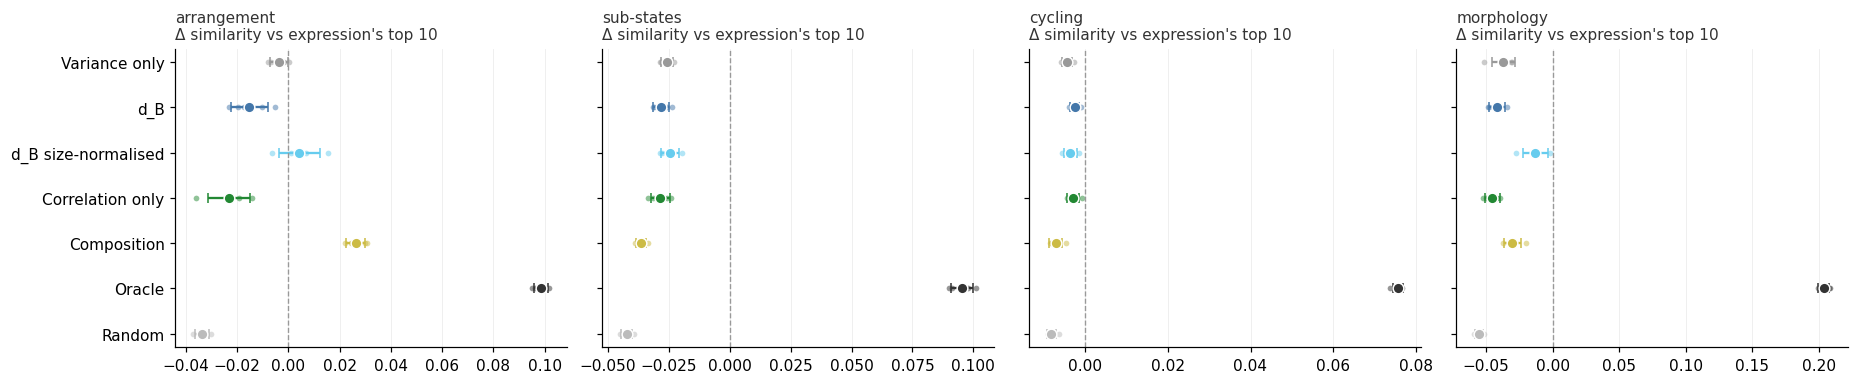

In [6]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(17, 3.6))
order = RANKERS[1:] + CONTROLS
for ax, t in zip(axes, TARGETS):
    seed_mean = RE.groupby("seed").mean(numeric_only=True)
    for y, m in enumerate(order):
        g = seed_mean[f"{t} | {m}"] - seed_mean[f"{t} | Expression"]
        ax.scatter(g, np.full(len(g), y), s=14, color=COLORS[m], alpha=0.5, lw=0)
        ax.errorbar(g.mean(), y, xerr=g.std(), fmt="o", ms=7, color=COLORS[m], mec="white", capsize=3)
    ax.axvline(0, color="#999999", lw=0.9, ls="--")
    ax.set_yticks(range(len(order)), order if t == TARGETS[0] else [])
    ax.invert_yaxis()
    ax.set_title(f"{t}\nΔ similarity vs expression's top 10", fontsize=10, loc="left", color="#333333")
    ax.grid(axis="x", color="#eeeeee", lw=0.6)
    ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## Results: target 4 (robustness, open search)

Overlap of the perturbed query's top 10 with the same distance's unperturbed top 10, and the composition lift of the
perturbed top 10; mean ± s.d. over seeds.

In [7]:
rows = []
for name in PERTURB:
    sm = RO[RO.perturbation == name].groupby("seed").mean(numeric_only=True)
    for m in RANKERS:
        rows.append({"perturbation": name, "distance": m,
                     **{k: f"{sm[f'{k} | {m}'].mean():.3f} ± {sm[f'{k} | {m}'].std():.3f}"
                        for k in ("overlap", "composition lift")}})
    ok = sm["overlap | d_B"].mean() >= sm["overlap | Expression"].mean() + 0.10
    print(f"{name}: d_B pass = {ok}")
pd.DataFrame(rows).set_index(["perturbation", "distance"])

depth ½: d_B pass = False
gene capture: d_B pass = False


overlap composition lift
perturbation distance                                           
depth ½      Expression           0.042 ± 0.001    0.403 ± 0.008
             Variance only        0.010 ± 0.002    0.343 ± 0.005
             d_B                  0.009 ± 0.001    0.323 ± 0.012
             d_B size-normalised  0.025 ± 0.010    0.304 ± 0.016
             Correlation only     0.633 ± 0.048    0.147 ± 0.060
gene capture Expression           0.665 ± 0.032    0.479 ± 0.009
             Variance only        0.318 ± 0.104    0.433 ± 0.018
             d_B                  0.297 ± 0.108    0.414 ± 0.037
             d_B size-normalised  0.374 ± 0.122    0.410 ± 0.038
             Correlation only     0.739 ± 0.081    0.233 ± 0.041

## Reading the results (Slurm job 24263, 1 Nov; breast, cap 200, seeds 0–4)

**Nothing passes; d_B is worse than expression on every target.** Re-ranking expression's 50 nearest by d_B moves
away from expression's picks and makes every target less similar to the query.

| Target | d_B gain over expression's top 10 | Best covariance ranker | Composition control | Oracle |
|---|---|---|---|---|
| Arrangement | −0.015 (0/5 seeds) | size-normalised +0.004 (4/5) | +0.026 | +0.098 |
| Sub-states | −0.028 (0/5) | size-normalised −0.025 | −0.036 | +0.095 |
| Cycling by class | −0.002 (0/5, p 0.06) | d_B −0.002 | −0.007 | +0.076 |
| Morphology | −0.042 (0/5) | size-normalised −0.013 | −0.030 | +0.204 |

- **Arrangement:** the spillover idea is not supported. Only size-normalised d_B gains, and less than picking by
  composition. Cell contacts follow composition, which expression already matches.
- **Cell state and morphology:** expression's own order is the best guide among its 50 candidates; every other ranker,
  composition included, does worse. Cell state within a class is a mean-expression property of those cells.
- **Robustness (open search):** halving the depth leaves expression and d_B with almost none of their top 10 (0.04 and
  0.01; both on unnormalised counts), while correlation only keeps 0.63. Under a per-gene capture shift expression keeps
  0.67, d_B 0.30, correlation only 0.74. Correlation is the robust one, as expected, but its composition lift is low
  (0.15–0.23), and d_B is less robust than expression.

**Bottom line.** In this section, among tiles that expression already matches, covariance does not find tiles that are
closer in arrangement, cell state or morphology. The only target where covariance has beaten expression is within-type
co-expression itself (`rerank.ipynb`, `metric_variants.ipynb`).